# Climate Feature Forecasting Model

## Executive Summary

This notebook develops, evaluates, saves, and operationalizes a **multi-output climate forecasting model** for the 2-hour ERA5 climate observations in the merged dataset.

- **Primary target:** all numeric climate variables
- **Explicitly excluded targets and inputs:** `Port 1` through `Port 5`
- **Default forecast interval:** 2 hours
- **Model:** Extra Trees Regressor with three historical climate intervals and calendar features
- **Evaluation:** chronological holdout to avoid training on future observations
- **Saved model:** `models/climate_model.joblib`

## 1. Scope and assumptions

The raw dataset contains climate observations and soil-moisture sensor readings. For this analysis, only climate variables are predicted. Latitude and longitude are retained as location metadata/features, while every `Port` column is excluded from both model training and output.

Forecasts are recursive: each newly predicted climate vector becomes an input for subsequent future intervals. Values are estimates and uncertainty grows as the forecast horizon increases.

In [9]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()
DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'merged_full_data.csv'
MODEL_DIR = PROJECT_ROOT / 'models'
MODEL_PATH = MODEL_DIR / 'climate_model.joblib'
RAW_PREDICTIONS_PATH = PROJECT_ROOT / 'data' / 'processed' / 'climate_predictions_with_actual.csv'
FORECAST_PATH = PROJECT_ROOT / 'climate_forecast.csv'
METADATA_PATH = MODEL_DIR / 'climate_model_metadata.json'

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from climate_forecasting import ClimateForecastModel, predict_entire_raw_dataset, climate_forecast

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (12, 6)
print(f'Project: {PROJECT_ROOT}')
print(f'Dataset: {DATA_PATH}')

Project: C:\Users\HomePC\Desktop\moisture-sensor
Dataset: C:\Users\HomePC\Desktop\moisture-sensor\data\processed\merged_full_data.csv


## 2. Dataset validation

This section confirms the data order, observation interval, dimensions, variables, and missing values before modeling.

In [10]:
raw = pd.read_csv(DATA_PATH, parse_dates=['valid_time'])
raw = raw.sort_values('valid_time').reset_index(drop=True)

print('Shape:', raw.shape)
print('Date range:', raw['valid_time'].min(), 'to', raw['valid_time'].max())
print('Rows with missing values:', int(raw.isna().any(axis=1).sum()))
print('Duplicate timestamps:', int(raw['valid_time'].duplicated().sum()))

interval_hours = raw['valid_time'].diff().dropna().median().total_seconds() / 3600
print('Median source interval (hours):', interval_hours)

ports = {f'Port {i}' for i in range(1, 6)}
climate_columns = [c for c in raw.select_dtypes(include='number').columns if c not in {'latitude', 'longitude'} and c not in ports]
print('Number of climate targets:', len(climate_columns))
print('Climate targets:', climate_columns)

raw.head()

Shape: (8817, 27)
Date range: 2023-02-28 20:00:00 to 2025-03-04 12:00:00
Rows with missing values: 0
Duplicate timestamps: 0
Median source interval (hours): 2.0
Number of climate targets: 19
Climate targets: ['d2m', 't2m', 'sp', 'tp', 'ssrd', 'strd', 'skt', 'snowc', 'sde', 'stl1', 'stl2', 'stl3', 'stl4', 'swvl1', 'swvl2', 'swvl3', 'swvl4', 'u10', 'v10']


,valid_time,d2m,t2m,latitude,longitude,sp,tp,ssrd,strd,skt,...,swvl2,swvl3,swvl4,u10,v10,Port 1,Port 2,Port 3,Port 4,Port 5
0,2023-02-28 20:00:00,284.82748,292.54553,0.1,37.8,87403.30,0.0,0.0,1217556.0,291.75702,...,0.161331,0.164734,0.17363,1.530060,0.355911,2533,2799,2764,2771,2765
1,2023-02-28 22:00:00,284.80720,291.08658,0.1,37.8,87322.70,0.0,0.0,1210456.0,289.91904,...,0.161331,0.164734,0.17363,1.622513,0.416901,2533,2799,2764,2771,2764
2,2023-03-01 00:00:00,284.67810,289.69907,0.1,37.8,87211.33,0.0,0.0,1175936.0,288.47370,...,0.161331,0.164734,0.17363,1.467438,0.315567,2533,2798,2764,2771,2763
3,2023-03-01 02:00:00,283.82343,289.02550,0.1,37.8,87244.08,0.0,0.0,1161795.2,287.18700,...,0.161316,0.164734,0.17363,0.907898,0.928314,2533,2798,2764,2771,2763
4,2023-03-01 04:00:00,283.31420,288.79987,0.1,37.8,87354.70,0.0,22410.0,1150341.0,286.41130,...,0.161316,0.164734,0.17363,0.576614,1.007843,2533,2798,2764,2771,2763


## 3. Model design

The forecaster uses:

1. Three lagged climate states (`lag 1` through `lag 3`) for every climate target.
2. Calendar features (hour, day-of-week, month, day-of-year, and cyclic encodings).
3. Latitude and longitude for spatial context.
4. Extra Trees regression for nonlinear relationships.
5. An 80%/20% chronological split with the latest 20% held out for testing.

This model does **not** use sensor Port values as features or targets.

In [11]:
model = ClimateForecastModel(DATA_PATH, interval_hours=2.0, lag_intervals=3, random_state=42).fit()
MODEL_DIR.mkdir(parents=True, exist_ok=True)
model.save(MODEL_PATH, METADATA_PATH)
print('Model saved to:', MODEL_PATH)
print('Training rows:', model.train_rows_)
print('Chronological test rows:', model.test_rows_)
print('Targets:', len(model.target_names))

Model saved to: C:\Users\HomePC\Desktop\moisture-sensor\models\climate_model.joblib
Training rows: 7051
Chronological test rows: 1763
Targets: 19


## 4. Test performance and metrics

Metrics are reported per climate feature and for all feature predictions flattened together.

- **R:** Pearson correlation coefficient
- **R-squared:** coefficient of determination
- **MAD:** median absolute deviation of prediction errors
- **MAE:** mean absolute error
- **MSE:** mean squared error
- **RMSE:** root mean squared error
- **MedAE:** median absolute error

In [12]:
metrics = model.metrics_.copy()
metrics_path = MODEL_DIR / 'climate_model_metrics.csv'
metrics.to_csv(metrics_path, index=False)
display(metrics.round(6))
print('Metrics saved to:', metrics_path)

overall = metrics[metrics['target'] == 'OVERALL_FLATTENED'].iloc[0]
for column in ['R', 'R2', 'MAD', 'MAE', 'MSE', 'RMSE', 'MedAE', 'MaxError']:
    print(f'{column}: {overall[column]:,.6f}')

,target,R,R2,MAD,MAE,MSE,RMSE,MedAE,MaxError
0,d2m,0.891715,0.729270,0.768567,0.961641,1.642928e+00,1.281767,0.740897,6.415394e+00
1,t2m,0.978745,0.955994,0.493805,0.633521,7.085830e-01,0.841774,0.490504,4.755469e+00
2,sp,0.845980,0.558831,56.287163,80.407870,1.012452e+04,100.620696,69.564269,3.187333e+02
3,tp,0.652068,0.277629,0.000008,0.000062,0.000000e+00,0.000301,0.000011,6.214000e-03
4,ssrd,0.988685,0.977123,12559.150000,86688.230580,3.339408e+10,182740.483380,12589.701852,1.469532e+06
5,strd,0.913303,0.828610,18729.069907,25384.522539,1.068817e+09,32692.770069,20795.524074,1.144405e+05
6,skt,0.985376,0.968827,0.638994,0.805218,1.167732e+00,1.080616,0.641781,7.210792e+00
7,snowc,NaN,1.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000e+00
8,sde,NaN,-80.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000e+00
9,stl1,0.985108,0.968948,0.429873,0.537260,4.837870e-01,0.695548,0.429714,3.032994e+00


Metrics saved to: C:\Users\HomePC\Desktop\moisture-sensor\models\climate_model_metrics.csv
R: 0.995431
R2: 0.990763
MAD: 0.160811
MAE: 5,903.072697
MSE: 1,813,837,453.222098
RMSE: 42,589.170610
MedAE: 0.160806
MaxError: 1,469,532.170370


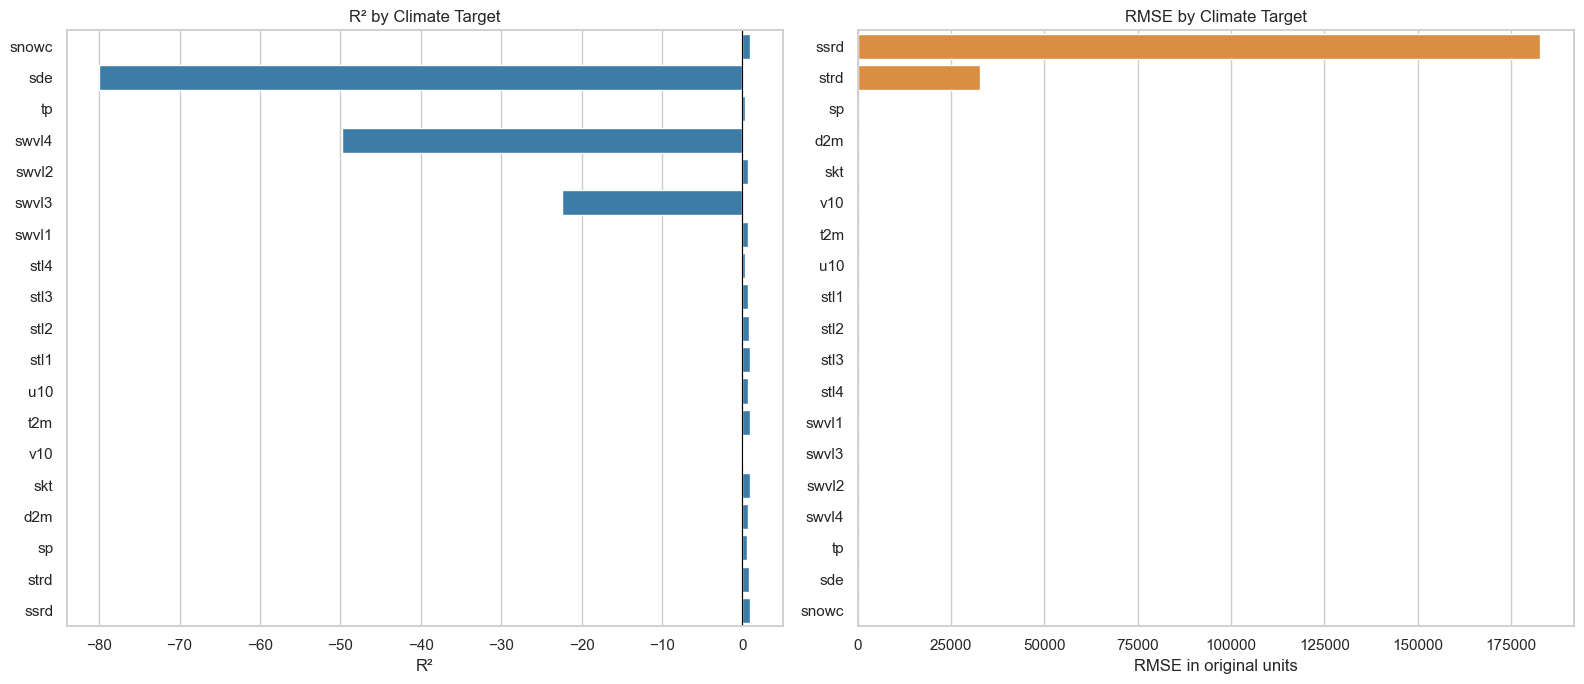

In [13]:
per_target = metrics[metrics['target'] != 'OVERALL_FLATTENED'].sort_values('RMSE')

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sns.barplot(data=per_target, x='R2', y='target', ax=axes[0], color='#2C7FB8')
axes[0].set_title('R² by Climate Target')
axes[0].set_xlabel('R²')
axes[0].set_ylabel('')
axes[0].axvline(0, color='black', linewidth=0.8)

sns.barplot(data=per_target.sort_values('RMSE', ascending=False), x='RMSE', y='target', ax=axes[1], color='#F28E2B')
axes[1].set_title('RMSE by Climate Target')
axes[1].set_xlabel('RMSE in original units')
axes[1].set_ylabel('')
plt.tight_layout()
plt.show()

## 5. Actual versus predicted performance

The plots below show the best-performing climate target and the target with the highest RMSE in the chronological holdout.

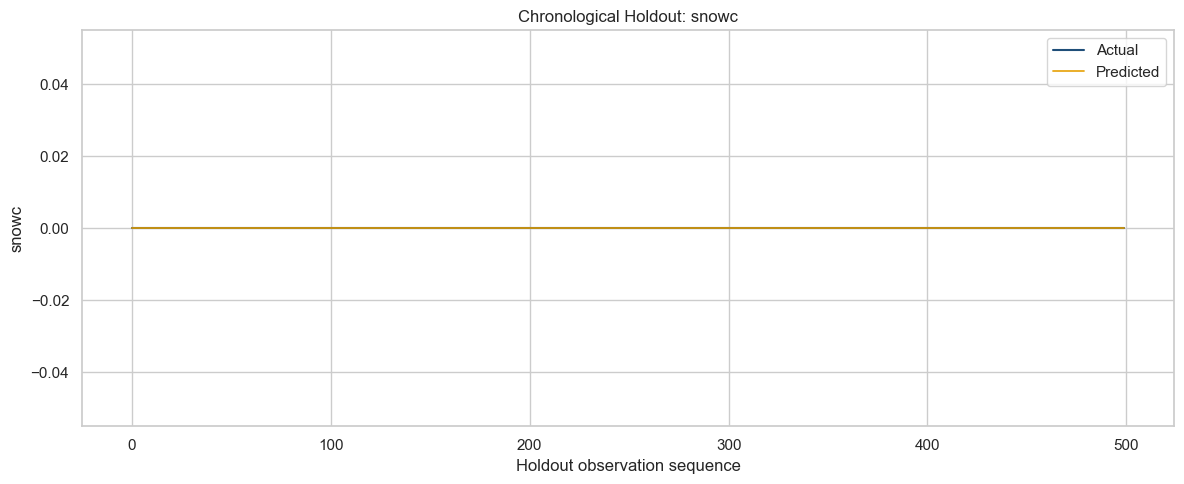

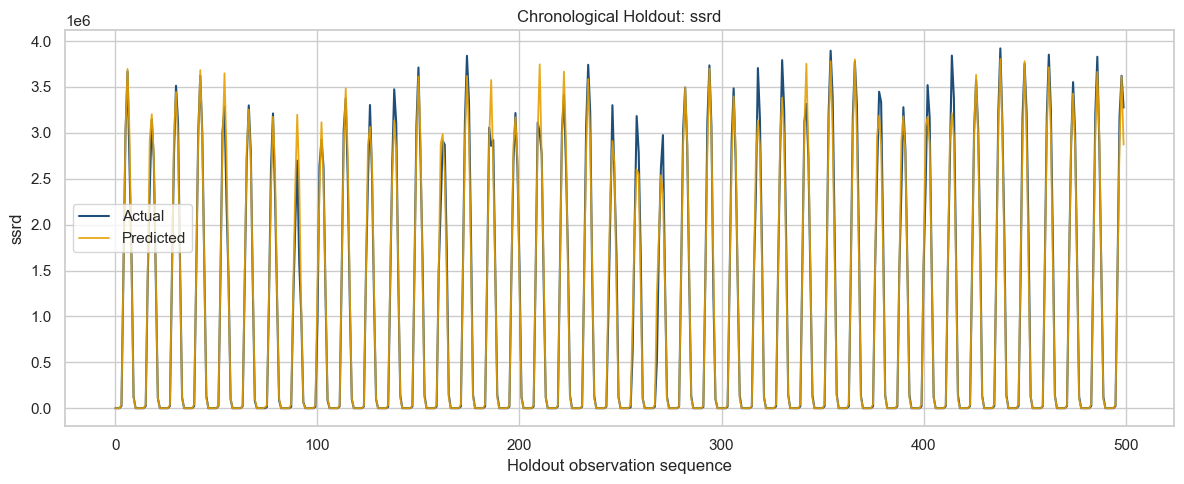

In [14]:
from climate_forecasting import load_raw_dataset
raw_interval, targets = load_raw_dataset(DATA_PATH)
interval = model._interval_frame(raw_interval)
features, labels = model.build_features(interval, targets)
split = int(len(features) * 0.80)
split = max(model.lag_intervals, min(split, len(features) - 1))
y_test = labels.iloc[split:].reset_index(drop=True)
y_pred = pd.DataFrame(model.model.predict(features.iloc[split:]), columns=targets)

per_target_for_plot = metrics[metrics['target'] != 'OVERALL_FLATTENED'].copy()
best_target = per_target_for_plot.sort_values('R2', ascending=False)['target'].iloc[0]
worst_target = per_target_for_plot.sort_values('RMSE', ascending=False)['target'].iloc[0]

for target_name in [best_target, worst_target]:
    fig, ax = plt.subplots(figsize=(12, 5))
    sample = min(500, len(y_test))
    ax.plot(y_test[target_name].iloc[-sample:].values, label='Actual', linewidth=1.5, color='#1F4E79')
    ax.plot(y_pred[target_name].iloc[-sample:].values, label='Predicted', linewidth=1.3, color='#E69F00', alpha=0.9)
    ax.set_title(f'Chronological Holdout: {target_name}')
    ax.set_xlabel('Holdout observation sequence')
    ax.set_ylabel(target_name)
    ax.legend()
    plt.tight_layout()
    plt.show()

## 6. Prediction function for the complete raw dataset

`predict_entire_raw_dataset()` adds two columns for each climate variable: `{variable}_actual` and `{variable}_predicted`. It never adds or models Port sensor targets.

In [15]:
raw_predictions = predict_entire_raw_dataset(
    data_path=DATA_PATH,
    output_path=RAW_PREDICTIONS_PATH,
    model_path=MODEL_PATH,
)
print('Output shape:', raw_predictions.shape)
print('Saved to:', RAW_PREDICTIONS_PATH)

actual_predicted_columns = [c for c in raw_predictions.columns if c.endswith('_actual') or c.endswith('_predicted')]
print('Actual/predicted column count:', len(actual_predicted_columns))
raw_predictions[['valid_time'] + actual_predicted_columns[:6]].head()

Output shape: (8817, 65)
Saved to: C:\Users\HomePC\Desktop\moisture-sensor\data\processed\climate_predictions_with_actual.csv
Actual/predicted column count: 38


,valid_time,d2m_actual,d2m_predicted,t2m_actual,t2m_predicted,sp_actual,sp_predicted
0,2023-02-28 20:00:00,284.82748,NaN,292.54553,NaN,87403.30,NaN
1,2023-02-28 22:00:00,284.80720,NaN,291.08658,NaN,87322.70,NaN
2,2023-03-01 00:00:00,284.67810,NaN,289.69907,NaN,87211.33,NaN
3,2023-03-01 02:00:00,283.82343,284.175678,289.02550,289.080841,87244.08,87268.198785
4,2023-03-01 04:00:00,283.31420,283.595544,288.79987,288.803998,87354.70,87365.879820


In [18]:
raw_predictions[['valid_time'] + actual_predicted_columns[:6]].tail()

,valid_time,d2m_actual,d2m_predicted,t2m_actual,t2m_predicted,sp_actual,sp_predicted
8812,2025-03-04 04:00:00,285.54074,285.273923,289.94275,289.870910,87193.310,87320.582077
8813,2025-03-04 06:00:00,286.70010,286.495995,295.66254,295.896488,87294.125,87373.298855
8814,2025-03-04 08:00:00,285.37695,286.138905,299.97083,298.590095,87301.670,87388.307272
8815,2025-03-04 10:00:00,283.36670,284.581916,302.11280,301.626251,87125.030,87201.394058
8816,2025-03-04 12:00:00,283.54794,284.459639,302.77650,302.006683,86958.220,87021.049928


## 7. Future forecast function

`climate_forecast(years, interval_hours=2.0, output_path=..., model_path=...)` generates recursive climate forecasts. The forecast frame is written to the requested CSV and contains no Port columns.

The demonstration below forecasts one year at the default two-hour interval.

In [19]:
YEARS_TO_FORECAST = 1
INTERVAL_HOURS = 2.0

future = climate_forecast(
    years=YEARS_TO_FORECAST,
    interval_hours=INTERVAL_HOURS,
    output_path=FORECAST_PATH,
    model_path=MODEL_PATH,
    data_path=DATA_PATH,
)
print('Forecast shape:', future.shape)
print('Forecast range:', future['valid_time'].min(), 'to', future['valid_time'].max())
print('Output file:', FORECAST_PATH)
display(future.head())

Forecast shape: (4383, 22)
Forecast range: 2025-03-04 14:00:00 to 2026-03-04 18:00:00
Output file: C:\Users\HomePC\Desktop\moisture-sensor\climate_forecast.csv


,valid_time,latitude,longitude,d2m,t2m,sp,tp,ssrd,strd,skt,...,stl1,stl2,stl3,stl4,swvl1,swvl2,swvl3,swvl4,u10,v10
0,2025-03-04 14:00:00,0.1,37.8,284.981223,301.054310,87007.602532,0.000019,1.555849e+06,1.358296e+06,304.549408,...,303.690027,298.776416,297.181943,296.159100,0.142566,0.169445,0.191171,0.177334,-2.487881,0.567111
1,2025-03-04 16:00:00,0.1,37.8,285.903919,297.665000,87059.137931,0.000002,1.022644e+05,1.319418e+06,298.688831,...,299.906741,298.636476,297.166306,296.181422,0.147303,0.170675,0.188930,0.176575,-1.244852,0.997833
2,2025-03-04 18:00:00,0.1,37.8,286.328661,294.831204,87239.013245,0.000003,-2.333333e-01,1.297181e+06,294.802012,...,296.884068,298.087182,296.799647,296.095400,0.148577,0.175942,0.196119,0.178301,-0.455024,1.575170
3,2025-03-04 20:00:00,0.1,37.8,286.772958,293.322362,87311.631625,0.000011,-2.962963e-02,1.293391e+06,293.094724,...,295.433758,297.639826,296.766211,296.114641,0.154106,0.178712,0.195586,0.177853,-0.101774,1.581236
4,2025-03-04 22:00:00,0.1,37.8,287.432909,291.901278,87296.272729,0.000018,2.407407e-02,1.301445e+06,291.542257,...,294.024337,296.859143,296.485463,296.088333,0.163717,0.187649,0.195131,0.177956,-0.226074,1.649729


In [9]:
assert MODEL_PATH.exists(), 'Saved climate model is missing.'
assert RAW_PREDICTIONS_PATH.exists(), 'Raw dataset prediction output is missing.'
assert FORECAST_PATH.exists(), 'Forecast CSV is missing.'

raw_pred_df = pd.read_csv(RAW_PREDICTIONS_PATH, nrows=2)
forecast_df = pd.read_csv(FORECAST_PATH, nrows=2)

assert not any(c.startswith('Port') for c in raw_pred_df.columns), 'A Port column appeared in predictions.'
assert not any(c.startswith('Port') for c in forecast_df.columns), 'A Port column appeared in future forecast.'
print('All deliverables created and Port exclusions verified.')

All deliverables created and Port exclusions verified.
